<a href="https://colab.research.google.com/github/HafizRizqi/MachineLearning_2026/blob/main/JS08/JS08_Tugas_Lab_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#🏵️Tugas Lab 2
1. Pilih salah satu dataset nyata dari sklearn.datasets (misalnya iris dataset atau digits dataset).

2. Lakukan clustering dengan HDBSCAN.

3. Laporkan hasil:
- Jumlah cluster yang terbentuk.

- Banyaknya noise.

- Visualisasi (gunakan PCA/TSNE untuk reduksi dimensi jika perlu, dikarenakan - visualisasi hanya dapat dilakukan hingga 3 dimensi).

4. Buat analisis singkat: apakah hasil clustering HDBSCAN sesuai dengan label asli dataset tersebut?

Langkah 0 — Instalasi library HDBSCAN

In [1]:
!pip install -q hdbscan

Langkah 1 — Import library

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import hdbscan

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

Langkah 2 — Upload dan Load Iris Dataset

In [3]:
from google.colab import files
uploaded = files.upload()

Saving iris.csv to iris.csv


In [12]:
df_iris = pd.read_csv('iris.csv')

# Memisahkan fitur dan label asli
nama_fitur = [kolom for kolom in df_iris.columns if kolom != 'species']

X = df_iris[nama_fitur].values

# Mengubah nama spesies menjadi label numerik
label_asli, nama_spesies = pd.factorize(df_iris['species'], sort=True)

# Menampilkan informasi dataset
print('Ukuran dataset:', df_iris.shape)
display(df_iris.head())

print('Jumlah data setiap spesies:')
print(df_iris['species'].value_counts())

print('\nKonversi label spesies:')
for i, nama in enumerate(nama_spesies):
    print(i, '=', nama)

Ukuran dataset: (150, 5)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Jumlah data setiap spesies:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

Konversi label spesies:
0 = setosa
1 = versicolor
2 = virginica


Langkah 3 — Standardisasi fitur

In [13]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print('Bentuk data setelah scaling:', X_scaled.shape)
print('Rata-rata fitur setelah scaling:', np.round(X_scaled.mean(axis=0), 3))

Bentuk data setelah scaling: (150, 4)
Rata-rata fitur setelah scaling: [-0. -0. -0. -0.]


Langkah 4 — Membuat model HDBSCAN

In [14]:
hdb = hdbscan.HDBSCAN(
    min_cluster_size=5,
    min_samples=5,
    metric='euclidean',
    cluster_selection_method='eom'
)

labels_hdb = hdb.fit_predict(X_scaled)

Langkah 5 — Menghitung jumlah cluster dan noise

Label -1 dihitung sebagai noise, bukan sebagai cluster. Karena itu jumlah cluster dihitung dengan mengurangi jumlah label unik dengan satu apabila label -1 ditemukan.

In [15]:
label_unik = np.unique(labels_hdb)
jumlah_cluster = len(label_unik) - (1 if -1 in label_unik else 0)
jumlah_noise = int(np.sum(labels_hdb == -1))
persentase_noise = jumlah_noise / len(labels_hdb) * 100

print('Jumlah cluster yang terbentuk:', jumlah_cluster)
print('Jumlah data noise:', jumlah_noise)
print(f'Persentase noise: {persentase_noise:.2f}%')

print('Distribusi anggota setiap label (-1 berarti noise):')
print(pd.Series(labels_hdb).value_counts().sort_index())

Jumlah cluster yang terbentuk: 2
Jumlah data noise: 2
Persentase noise: 1.33%
Distribusi anggota setiap label (-1 berarti noise):
-1     2
 0    99
 1    49
Name: count, dtype: int64


Langkah 6 — Reduksi dimensi dengan PCA

Iris mempunyai empat fitur, sedangkan visualisasi dua dimensi lebih mudah dibaca. PCA mereduksi empat fitur menjadi dua komponen utama. PCA hanya dipakai untuk visualisasi; model HDBSCAN tetap dilatih menggunakan seluruh empat fitur yang sudah distandardisasi.

In [16]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print('Variansi yang dijelaskan PC1 dan PC2:', np.round(pca.explained_variance_ratio_, 4))
print('Total variansi yang dijelaskan:', round(pca.explained_variance_ratio_.sum(), 4))

Variansi yang dijelaskan PC1 dan PC2: [0.7296 0.2285]
Total variansi yang dijelaskan: 0.9581


Langkah 7 — Visualisasi hasil HDBSCAN dan label asli

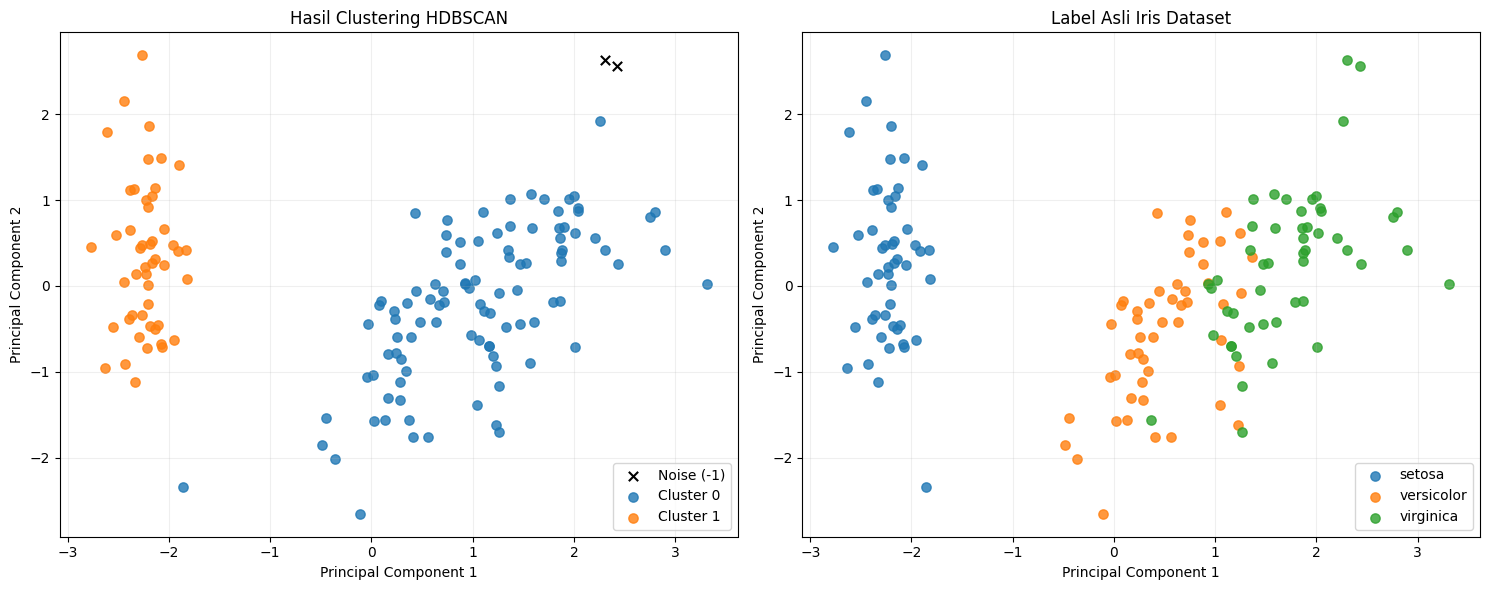

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Visualisasi label hasil HDBSCAN
for cluster_id in sorted(np.unique(labels_hdb)):
    mask = labels_hdb == cluster_id
    if cluster_id == -1:
        axes[0].scatter(
            X_pca[mask, 0], X_pca[mask, 1],
            marker='x', color='black', s=45, label='Noise (-1)'
        )
    else:
        axes[0].scatter(
            X_pca[mask, 0], X_pca[mask, 1],
            s=45, alpha=0.8, label=f'Cluster {cluster_id}'
        )
axes[0].set_title('Hasil Clustering HDBSCAN')
axes[0].set_xlabel('Principal Component 1')
axes[0].set_ylabel('Principal Component 2')
axes[0].legend()
axes[0].grid(alpha=0.2)

# Visualisasi label spesies asli
for species_id, species_name in enumerate(nama_spesies):
    mask = label_asli == species_id
    axes[1].scatter(
        X_pca[mask, 0], X_pca[mask, 1],
        s=45, alpha=0.8, label=species_name
    )
axes[1].set_title('Label Asli Iris Dataset')
axes[1].set_xlabel('Principal Component 1')
axes[1].set_ylabel('Principal Component 2')
axes[1].legend()
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

Grafik kiri menunjukkan label cluster dari HDBSCAN, sedangkan grafik kanan menunjukkan spesies asli dataset. Titik noise pada grafik HDBSCAN ditampilkan dengan tanda silang hitam. Perbandingan kedua grafik membantu melihat apakah kelompok hasil HDBSCAN mendekati pembagian spesies asli.

Langkah 8 — Membandingkan cluster dengan label spesies asli

In [18]:
ari = adjusted_rand_score(label_asli, labels_hdb)

# Ubah label asli menjadi nama spesies agar tabel lebih mudah dibaca
label_asli_nama = [nama_spesies[i] for i in label_asli]
tabel_perbandingan = pd.crosstab(
    pd.Series(labels_hdb, name='Cluster HDBSCAN'),
    pd.Series(label_asli_nama, name='Spesies Asli')
)

print(f'Adjusted Rand Index (ARI): {ari:.4f}')
display(tabel_perbandingan)

Adjusted Rand Index (ARI): 0.5394


Spesies Asli,setosa,versicolor,virginica
Cluster HDBSCAN,,,
-1,0,0,2
0,1,50,48
1,49,0,0


Nomor cluster HDBSCAN belum tentu sama dengan nomor spesies asli. Oleh karena itu, perbandingan tidak dilakukan dengan mencocokkan angka label secara langsung. Adjusted Rand Index (ARI) digunakan untuk mengukur kesesuaian dua pembagian kelompok tanpa mensyaratkan nomor labelnya sama. Nilai ARI mendekati 1 menunjukkan kesesuaian yang tinggi, sedangkan nilai sekitar 0 menunjukkan kesesuaian yang tidak lebih baik daripada pengelompokan acak.

Langkah 9 — Eksperimen parameter

In [19]:
daftar_parameter = [
    {'min_cluster_size': 5, 'min_samples': 3},
    {'min_cluster_size': 5, 'min_samples': 5},
    {'min_cluster_size': 10, 'min_samples': 5},
    {'min_cluster_size': 15, 'min_samples': 5},
    {'min_cluster_size': 10, 'min_samples': 10}
]

hasil_parameter = []
for parameter in daftar_parameter:
    model = hdbscan.HDBSCAN(
        min_cluster_size=parameter['min_cluster_size'],
        min_samples=parameter['min_samples'],
        metric='euclidean',
        cluster_selection_method='eom'
    )
    label_uji = model.fit_predict(X_scaled)
    label_uji_unik = np.unique(label_uji)
    n_cluster = len(label_uji_unik) - (1 if -1 in label_uji_unik else 0)
    n_noise = int(np.sum(label_uji == -1))

    hasil_parameter.append({
        'min_cluster_size': parameter['min_cluster_size'],
        'min_samples': parameter['min_samples'],
        'Jumlah Cluster': n_cluster,
        'Jumlah Noise': n_noise,
        'Noise (%)': round(n_noise / len(label_uji) * 100, 2),
        'ARI': round(adjusted_rand_score(label_asli, label_uji), 4)
    })

display(pd.DataFrame(hasil_parameter))

,min_cluster_size,min_samples,Jumlah Cluster,Jumlah Noise,Noise (%),ARI
0,5,3,2,2,1.33,0.5394
1,5,5,2,2,1.33,0.5394
2,10,5,2,2,1.33,0.5394
3,15,5,2,2,1.33,0.5394
4,10,10,2,2,1.33,0.5394


Hasil HDBSCAN dapat berubah ketika min_cluster_size dan min_samples diubah. Sel berikut membandingkan beberapa kombinasi parameter. Eksperimen ini membantu melihat pengaruh parameter terhadap jumlah cluster dan jumlah noise. ARI ditampilkan sebagai informasi perbandingan dengan label asli, bukan sebagai masukan untuk proses fitting model.

# Analisis hasil
1. Berdasarkan hasil clustering menggunakan algoritma HDBSCAN, terbentuk sebanyak **2 cluster** dari dataset Iris, yaitu Cluster 0 dan Cluster 1.

2. Terdapat **2 data yang dikategorikan sebagai noise** dari total 150 data, yaitu sebesar 1,33%. Kedua data tersebut berasal dari spesies Virginica. Hal ini menunjukkan bahwa sebagian besar data berhasil dikelompokkan ke dalam cluster oleh algoritma HDBSCAN.

3. Berdasarkan visualisasi PCA, Cluster 1 sebagian besar berisi spesies Setosa yang terlihat terpisah dari kelompok lainnya. Sementara itu, Cluster 0 menggabungkan sebagian besar spesies Versicolor dan Virginica. Hal ini menunjukkan bahwa HDBSCAN mampu memisahkan spesies Setosa dengan cukup baik, tetapi belum mampu membedakan Versicolor dan Virginica menjadi dua cluster yang terpisah.

4. Nilai Adjusted Rand Index (ARI) sebesar **0,5394** menunjukkan adanya kesesuaian antara hasil clustering dengan label spesies asli, meskipun hasil pengelompokannya belum sepenuhnya sama. Berdasarkan tabel perbandingan, sebagian besar Setosa masuk ke Cluster 1, sedangkan Versicolor dan Virginica sebagian besar masuk ke Cluster 0.

# Kesimpulan
Berdasarkan percobaan yang telah dilakukan, algoritma HDBSCAN berhasil membentuk 2 cluster dengan 2 data yang dikategorikan sebagai noise atau sebesar 1,33% dari total 150 data Iris. Hasil visualisasi PCA menunjukkan bahwa sebagian besar spesies Setosa berhasil dikelompokkan secara terpisah, sedangkan spesies Versicolor dan Virginica masih tergabung dalam satu cluster. Nilai ARI sebesar 0,5394 menunjukkan adanya kesesuaian sebagian antara hasil clustering dengan label spesies asli. Perbedaan ini terjadi karena HDBSCAN melakukan pengelompokan berdasarkan kepadatan data tanpa menggunakan label spesies sebagai acuan. Dengan demikian, hasil clustering tidak harus selalu menghasilkan jumlah cluster yang sama dengan jumlah kategori pada label asli dataset.